1. Downlaod the data

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from dataset.data import download_udacity_dataset
from src.extract_features import extract_features

In [2]:
download_udacity_dataset()

Dataset already exists. Skipping download.


2. preprocessing

In [3]:
#Shape
df = pd.read_csv('data/training_frames_keypoints.csv')
print(df.shape)
print(df.head(2))
print("Total Nan:",df.isnull().sum().sum())
print(df.isnull().sum()[df.isnull().sum()>0])

(3462, 137)
              Unnamed: 0     0     1     2      3     4      5     6      7  \
0      Luis_Fonsi_21.jpg  45.0  98.0  47.0  106.0  49.0  110.0  53.0  119.0   
1  Lincoln_Chafee_52.jpg  41.0  83.0  43.0   91.0  45.0  100.0  47.0  108.0   

      8  ...   126    127   128    129   130    131   132    133   134    135  
0  56.0  ...  83.0  119.0  90.0  117.0  83.0  119.0  81.0  122.0  77.0  122.0  
1  51.0  ...  85.0  122.0  94.0  120.0  85.0  122.0  83.0  122.0  79.0  122.0  

[2 rows x 137 columns]
Total Nan: 0
Series([], dtype: int64)


# Mechanistic Interpretability: Tensor Format

When extracting feature maps from a neural network, it is critical to understand how the framework organizes the dimensions of the data. The two standard formats are **NCHW** and **NHWC**.

### 1. PyTorch: NCHW (Channels First)
PyTorch uses the `[Batch, Channels, Height, Width]` format.

*   **Layout:** The color channels (e.g., RGB or the 32/64 filters of a Conv layer) are placed before the spatial dimensions.
*   **Why PyTorch uses it:** Historically, PyTorch was built around NVIDIA's cuDNN library, which was highly optimized for the NCHW memory layout. This makes it highly efficient for deep learning research and tensor operations on NVIDIA GPUs.
*   **How to slice:** To extract a single filter (channel) from a tensor in PyTorch, you slice the second dimension: `tensor[batch, channel, :, :]`.

### 2. Keras/TensorFlow: NHWC (Channels Last)
Keras uses the `[Batch, Height, Width, Channels]` format.

*   **Layout:** The color channels are placed at the very end, after the spatial dimensions.
*   **Why Keras uses it:** This layout is optimized for "memory coalescing" on modern GPUs and TPUs. It allows the hardware to read the RGB values of a single pixel in one fast memory operation.
*   **How to slice:** To extract a single filter in Keras, you slice the last dimension: `tensor[batch, :, :, channel]`.

---

### The Matplotlib Gotcha
When visualizing these tensors, `matplotlib` expects an image to be in **HWC** (Height, Width, Channels) format.

Because PyTorch outputs **NCHW**, you often have to `permute` or transpose the tensor before plotting it. Additionally, you must call `.detach().cpu().numpy()` on the PyTorch tensor first, as `matplotlib` cannot plot tensors that are attached to the computation graph (gradients).

In [4]:
features = extract_features()
for f in features:
    print(f.shape)

torch.Size([1, 32, 93, 93])
torch.Size([1, 64, 44, 44])
torch.Size([1, 128, 21, 21])
torch.Size([1, 256, 10, 10])


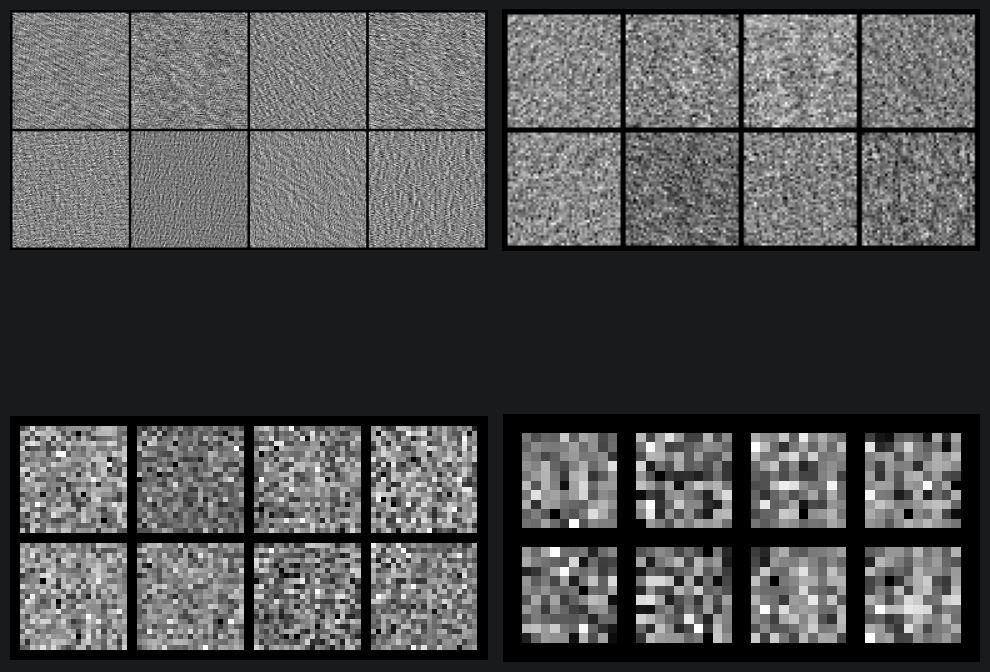

In [5]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, feature in zip(axes.flat, features):
    # Treat the first 8 channels as 8 single-channel images.
    channel_maps = feature.detach()[0, :8].unsqueeze(1)  # [8, 1, H, W]
    grid = make_grid(
        channel_maps,
        nrow=4,
        normalize=True,
        scale_each=True,
        padding=2,
    )

    ax.imshow(grid.permute(1, 2, 0).cpu().numpy())  # CHW -> HWC
    ax.axis("off")

plt.tight_layout()
plt.show()
